# Tenere i numeri in scala, e dove mettere l'operazione che lo fa

*Anatomia di un LLM* · capitolo 5, L'attenzione e il blocco · script `03-08`, `scripts/03_08_normalizzazione.py`

Impilando decine di blocchi i numeri tendono a crescere o a spegnersi. Si
rimedia normalizzandoli, e il punto interessante non e' come si normalizza ma
dove: la stessa operazione, spostata di due righe, decide se una pila profonda
si addestra o no.

Si esegue con `python3 scripts/03_08_normalizzazione.py`
e dura circa 10 secondi.

> **Per riottenere i numeri del libro** esegui le celle in ordine, dalla prima. Il seme si fissa una volta sola, in `prepara()`: rieseguire una cella a metà cambia i numeri casuali di tutte quelle dopo.

[Apri in Colab](https://colab.research.google.com/github/fcollova/llm-anatomy/blob/main/notebooks/03_08_normalizzazione.ipynb) · la prima cella scarica il codice, se non lo trova accanto.

In [ ]:
# Porta il notebook nella cartella che contiene llm_anatomy/, da dovunque
# sia stato aperto: gli script si eseguono da li', e cosi' anche le celle.
import os
import subprocess
import sys
from pathlib import Path

radice = next((p for p in [Path.cwd(), *Path.cwd().parents]
               if (p / "llm_anatomy").is_dir()), None)

if radice is None:
    # Il notebook e' stato aperto da solo, per esempio su Colab: il codice, il
    # testo e il modello addestrato si scaricano una volta, qui accanto.
    REPO, RAMO, CARTELLA = "fcollova/llm-anatomy", "main", ""
    copia = Path("anatomia-di-un-llm")
    if not copia.exists():
        esito = subprocess.run(
            ["git", "clone", "-q", "--depth", "1", "--branch", RAMO,
             f"https://github.com/{REPO}.git", str(copia)], capture_output=True)
        if esito.returncode != 0:
            raise SystemExit("Non riesco a scaricare il codice da github.com/"
                             + REPO + ": " + esito.stderr.decode()[-300:])
    radice = copia / CARTELLA

os.chdir(radice)
sys.path.insert(0, str(Path.cwd()))

In [ ]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from llm_anatomy.config import AgoGPTConfig
from llm_anatomy.model import Blk, RMSNorm
from llm_anatomy.utils import (conta_parametri, figura, prepara, stile_figure,
                               tabella, titolo, verifica)

prepara()

[ambiente] torch 2.13.0+cpu  device=cpu  threads=8  seed=1337


device(type='cpu')

In [ ]:
titolo("Due modi di normalizzare")
d = 256
x = torch.randn(4, 16, d)
ln = nn.LayerNorm(d, bias=False)
rms = RMSNorm(d)
y_ln, y_rms = ln(x), rms(x)
print(f"  media dell'ingresso:  {x.mean():+.4f}")
print(f"  media dopo LayerNorm: {y_ln.mean():+.4f}")
print(f"  media dopo RMSNorm:   {y_rms.mean():+.4f}")
print(f"  scarto massimo fra le due uscite: {(y_ln - y_rms).abs().max():.4f}")
print(f"  parametri: LayerNorm {conta_parametri(ln)}, RMSNorm {conta_parametri(rms)}")


Due modi di normalizzare
------------------------
  media dell'ingresso:  -0.0001
  media dopo LayerNorm: +0.0000
  media dopo RMSNorm:   +0.0001
  scarto massimo fra le due uscite: 0.1711
  parametri: LayerNorm 256, RMSNorm 256


In [ ]:
titolo("Quando coincidono")
x0 = x - x.mean(dim=-1, keepdim=True)
verifica(torch.allclose(ln(x0), rms(x0), atol=1e-5),
         "senza media da sottrarre, LayerNorm e RMSNorm fanno la stessa cosa")
print("  e' l'osservazione da cui nasce RMSNorm: la sottrazione della media non")
print("  serviva, e costa una passata in piu' sui dati")


Quando coincidono
-----------------
  [verifica superata] senza media da sottrarre, LayerNorm e RMSNorm fanno la stessa cosa
  e' l'osservazione da cui nasce RMSNorm: la sottrazione della media non
  serviva, e costa una passata in piu' sui dati


In [ ]:
titolo("Ventiquattro blocchi, e il gradiente")
N_BLOCCHI = 24
cfg = AgoGPTConfig(d_model=128, n_head=4, block_size=64, vocab_size=93, act="gelu")
risultati = {}
for etichetta, pre in (("pre-norm", True), ("post-norm", False)):
    torch.manual_seed(1337)
    blocchi = nn.ModuleList([Blk(cfg, pre_norm=pre) for _ in range(N_BLOCCHI)])
    x = torch.randn(2, 64, cfg.d_model, requires_grad=True)
    h = x
    for b in blocchi:
        h, _ = b(h)
    h.pow(2).mean().backward()
    norme = [float(b.attn.wq.weight.grad.norm()) for b in blocchi]
    risultati[etichetta] = norme

righe = []
for i in (0, 5, 11, 17, 23):
    pre, post = risultati["pre-norm"][i], risultati["post-norm"][i]
    righe.append([i, f"{pre:.3e}", f"{post:.3e}", f"{pre / max(post, 1e-30):.0f}x"])
tabella(["blocco", "pre-norm", "post-norm", "rapporto"], righe)

rapporto_medio = (sum(risultati["pre-norm"]) / sum(risultati["post-norm"]))
print(f"  il gradiente post-norm e' in media {rapporto_medio:.0f} volte piu'")
print("  piccolo di quello pre-norm, a ogni profondita'")
verifica(rapporto_medio > 100,
         "attraverso 24 blocchi post-norm il gradiente si attenua di oltre due "
         "ordini di grandezza")
print("  la differenza non e' nella distribuzione lungo la pila -- in entrambi")
print("  gli schemi i primi blocchi ricevono piu' segnale degli ultimi -- ma")
print("  nella scala assoluta: nel post-norm ogni blocco normalizza il flusso")
print("  residuo, e il percorso diretto dall'ingresso all'uscita non esiste")
print("  piu'. E' la ragione del warmup nel paper del 2017 e dell'instabilita'")
print("  che si osservava sopra i dodici blocchi")


Ventiquattro blocchi, e il gradiente
------------------------------------
blocco   pre-norm  post-norm  rapporto
------  ---------  ---------  --------
0       5.126e-02  6.407e-08   800092x
5       3.604e-02  4.725e-08   762658x
11      3.207e-02  4.361e-08   735415x
17      2.448e-02  3.570e-08   685531x
23      1.777e-02  3.058e-08   581152x
  il gradiente post-norm e' in media 693926 volte piu'
  piccolo di quello pre-norm, a ogni profondita'
  [verifica superata] attraverso 24 blocchi post-norm il gradiente si attenua di oltre due ordini di grandezza
  la differenza non e' nella distribuzione lungo la pila -- in entrambi
  gli schemi i primi blocchi ricevono piu' segnale degli ultimi -- ma
  nella scala assoluta: nel post-norm ogni blocco normalizza il flusso
  residuo, e il percorso diretto dall'ingresso all'uscita non esiste
  piu'. E' la ragione del warmup nel paper del 2017 e dell'instabilita'
  che si osservava sopra i dodici blocchi



Come cresce il flusso
---------------------


blocco  pre-norm  post-norm
------  --------  ---------
0          11,45      11,31
11         14,25      11,31
23         17,40      11,31
  nel pre-norm la norma cresce lungo la pila, perche' ogni blocco
  aggiunge al flusso residuo senza che nulla lo rinormalizzi: e' il
  motivo per cui serve una norma finale prima della testa di uscita


  [figura] outputs/figures/03-08_prenorm_postnorm.pdf


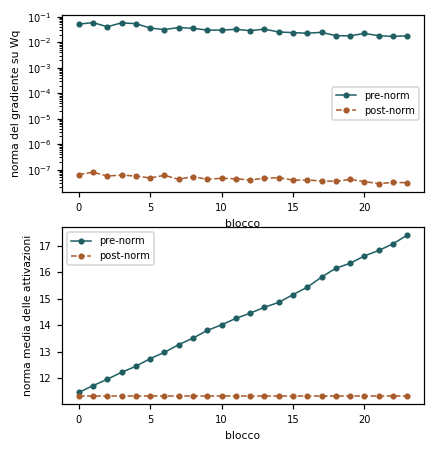

In [ ]:
titolo("Come cresce il flusso")
attivazioni = {}
for etichetta, pre in (("pre-norm", True), ("post-norm", False)):
    torch.manual_seed(1337)
    blocchi = nn.ModuleList([Blk(cfg, pre_norm=pre) for _ in range(N_BLOCCHI)])
    h = torch.randn(2, 64, cfg.d_model)
    serie = []
    with torch.no_grad():
        for b in blocchi:
            h, _ = b(h)
            serie.append(float(h.norm(dim=-1).mean()))
    attivazioni[etichetta] = serie
righe = []
for i in (0, 11, 23):
    righe.append([i,
                  f"{attivazioni['pre-norm'][i]:.2f}".replace(".", ","),
                  f"{attivazioni['post-norm'][i]:.2f}".replace(".", ",")])
tabella(["blocco", "pre-norm", "post-norm"], righe)
print("  nel pre-norm la norma cresce lungo la pila, perche' ogni blocco")
print("  aggiunge al flusso residuo senza che nulla lo rinormalizzi: e' il")
print("  motivo per cui serve una norma finale prima della testa di uscita")

fig, ax = plt.subplots(2, 1, figsize=(stile_figure(), 4.6))
for etichetta, norme in risultati.items():
    ax[0].semilogy(norme, marker="o", ms=3, lw=1, label=etichetta)
ax[0].set_xlabel("blocco")
ax[0].set_ylabel("norma del gradiente su Wq")
ax[0].legend()
for etichetta, serie in attivazioni.items():
    ax[1].plot(serie, marker="o", ms=3, lw=1, label=etichetta)
ax[1].set_xlabel("blocco")
ax[1].set_ylabel("norma media delle attivazioni")
ax[1].legend()
figura(fig, "03-08_prenorm_postnorm")

## Da provare

porta i blocchi da 24 a 48 e rifai il confronto sui gradienti.